# 03 · One setting at a time

**The question.** Practitioners often say that a handful of training settings decide whether deep learning works on retail
demand, and that getting them wrong mostly makes the model underfit (claims 1 and 2 of the four in notebook 01). Each card below changes one setting away from the recipe and compares the
two runs on every series.

In [1]:
import sys, os
try: import m5knobs  # noqa: F401  (installed with pip install -e .)
except ImportError: sys.path.insert(0, os.path.abspath(".."))  # run from notebooks/
from m5knobs import data, paths, experiments
from m5knobs.figures import cards, early_stopping

The five pairs. The clipping card uses the recipe's Tweedie loss. The other four use Huber δ5 instead, so the scaler card is
not confounded: Tweedie's output link anchors on RevIN's window mean (`loc`), which would break mechanically under MinMax
scaling, while Huber has no such dependence, so the scaler comparison stays fair. Their verdicts are about each setting under
Huber. Apart from the loss, the "with" run is the recipe, except on the early-stopping card, where both runs have the
minimum-steps guard off. The last column says whether both runs train on the same loss scale.

In [2]:
import json, pandas as pd
from IPython.display import Image, Markdown, display
display(pd.DataFrame(experiments.F3_ROWS, columns=["card", "loss", "without (arm)", "with (arm)", "same loss scale"]))

,card,loss,without (arm),with (arm),same loss scale
0,No gradient clipping,Tweedie,f2_noclip,f2_clip,True
1,Early-stop window 250 steps,Huber δ5,f3_patience250,f3_fix_noguard,True
2,Input window 13 weeks,Huber δ5,f3_input13,f3_fix,False
3,MinMax scaler,Huber δ5 (≈ MSE on MinMax scale),f3_minmax,f3_fix,False
4,MAE loss,MAE vs Huber δ5,f3_mae,f3_fix,False


**How to read a card.** Top: the knob and what it does. Red column = without (the mistake), blue = with (the recipe). Rows: the
three example series from notebook 01, actuals in black, forecasts from each origin in color. Bottom: WAPE and bias over all
series, the verdict on the "without" run (rule in notebook 01), and the seed-noise bar. The headline and the "what moved" text are
generated from the results. Under each card, the verdict and the numbers are repeated as text.

In [3]:
pngs = {os.path.basename(p)[5:-4]: p for p in cards.draw() if p.endswith(".png")}
V = json.load(open(os.path.join(paths.RESULTS, "card_verdicts.json")))
C, noise = {c["key"]: c for c in cards.CARDS}, data.SEED_NOISE

### Gradient clipping

**Claim:** clip the gradients when training with a likelihood loss. Both runs use the Tweedie loss. Notebook 04 looks at clipping
in more depth. The middle panels show the gradient norm per step; the dashed line is AutoClip's threshold.

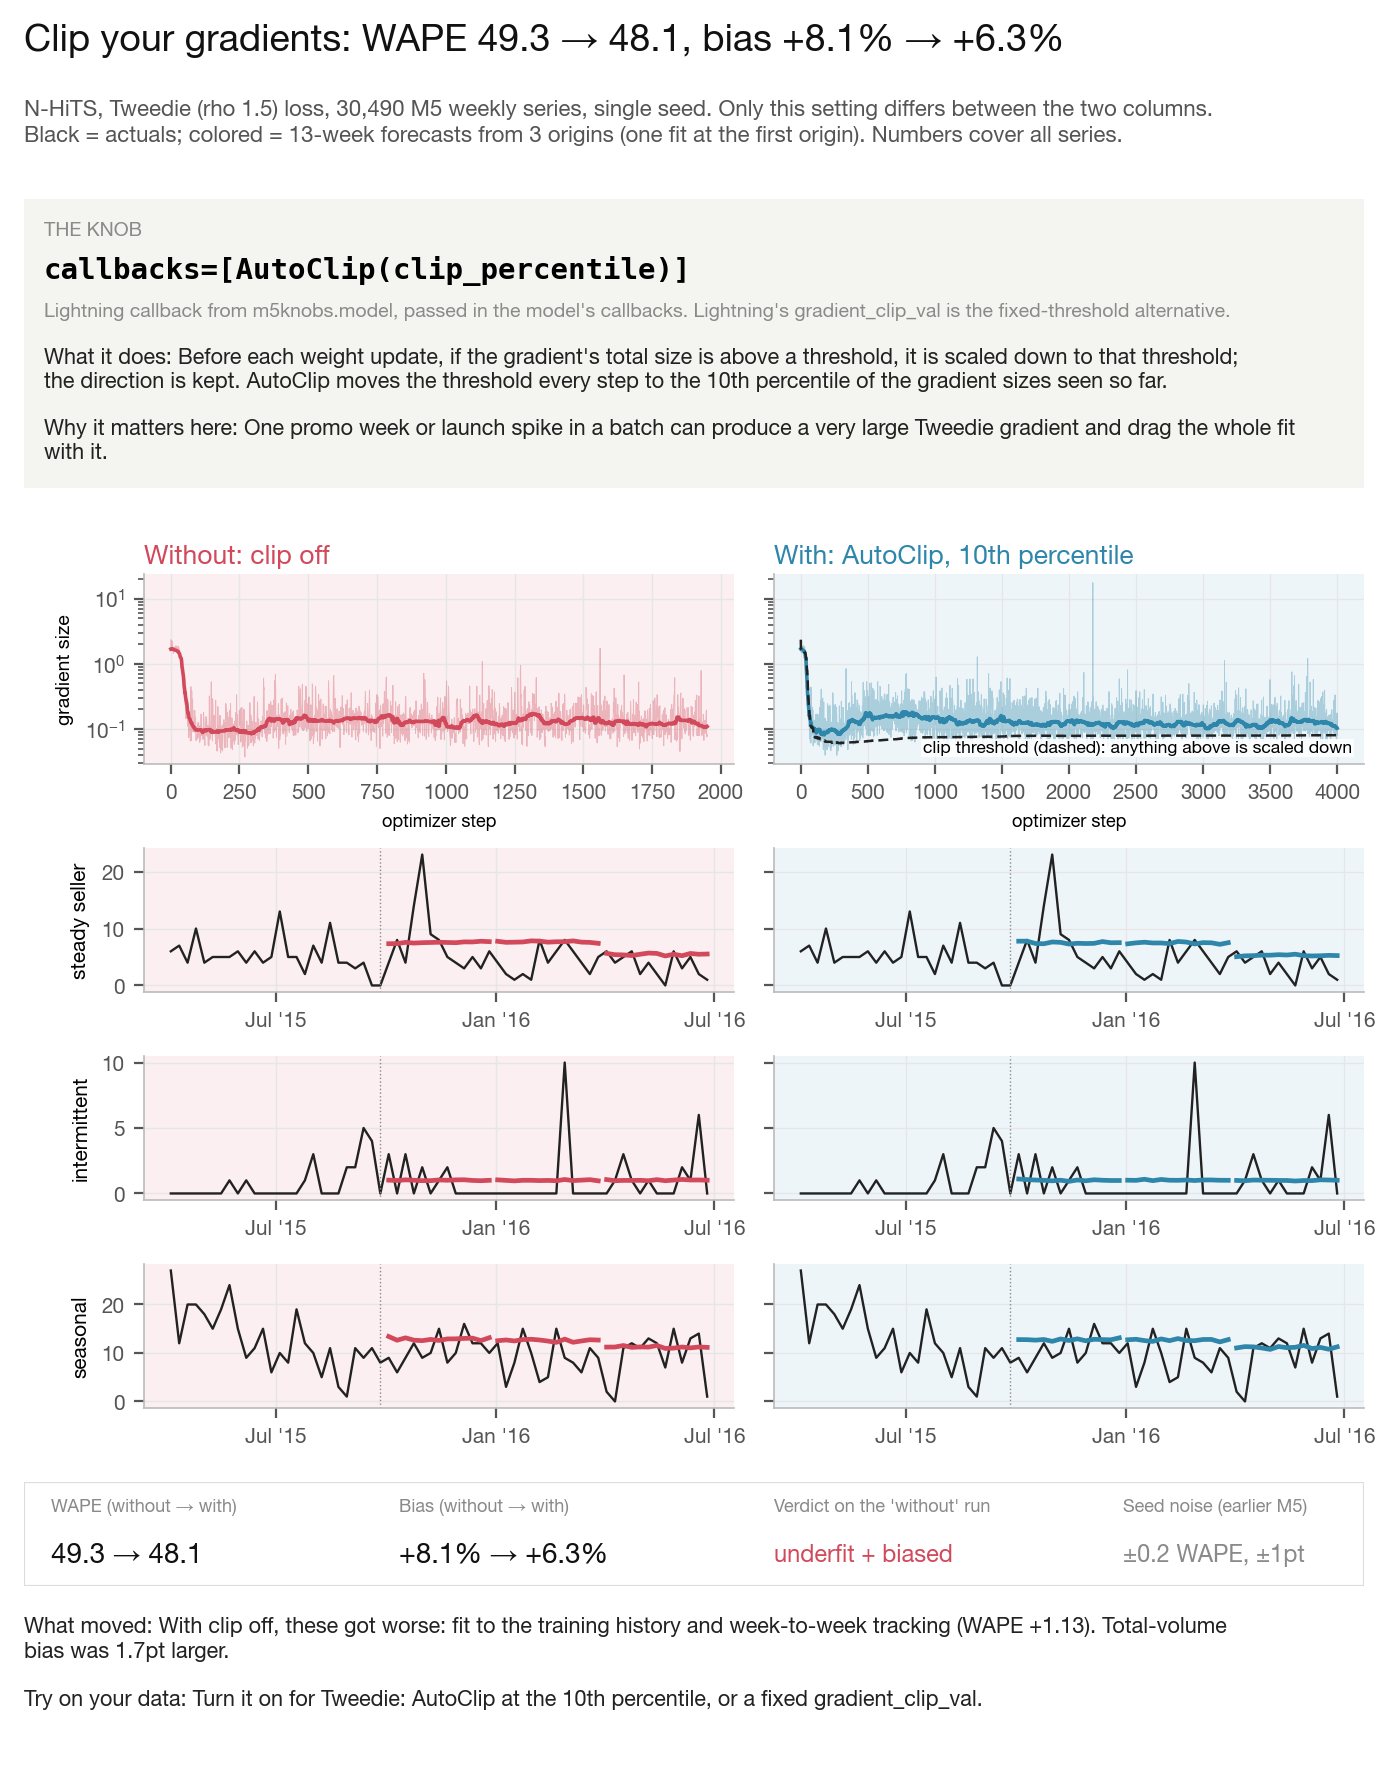

Compared: `clip off` (without) vs `AutoClip, 10th percentile` (with). **Verdict on the 'without' run: underfit and biased.** WAPE 49.27 → 48.14, bias +8.1% → +6.3%. With clip off, these got worse: fit to the training history and week-to-week tracking (WAPE +1.13). Total-volume bias was 1.7pt larger.

In [4]:
display(Image(pngs["clipping"], width=800))
display(Markdown(cards.verdict_text(C["clipping"], V["clipping"])))

### Input window

**Claim:** show the model a full year of history. Weekly retail demand repeats yearly, and a window shorter than a year cannot see
last year's same weeks.

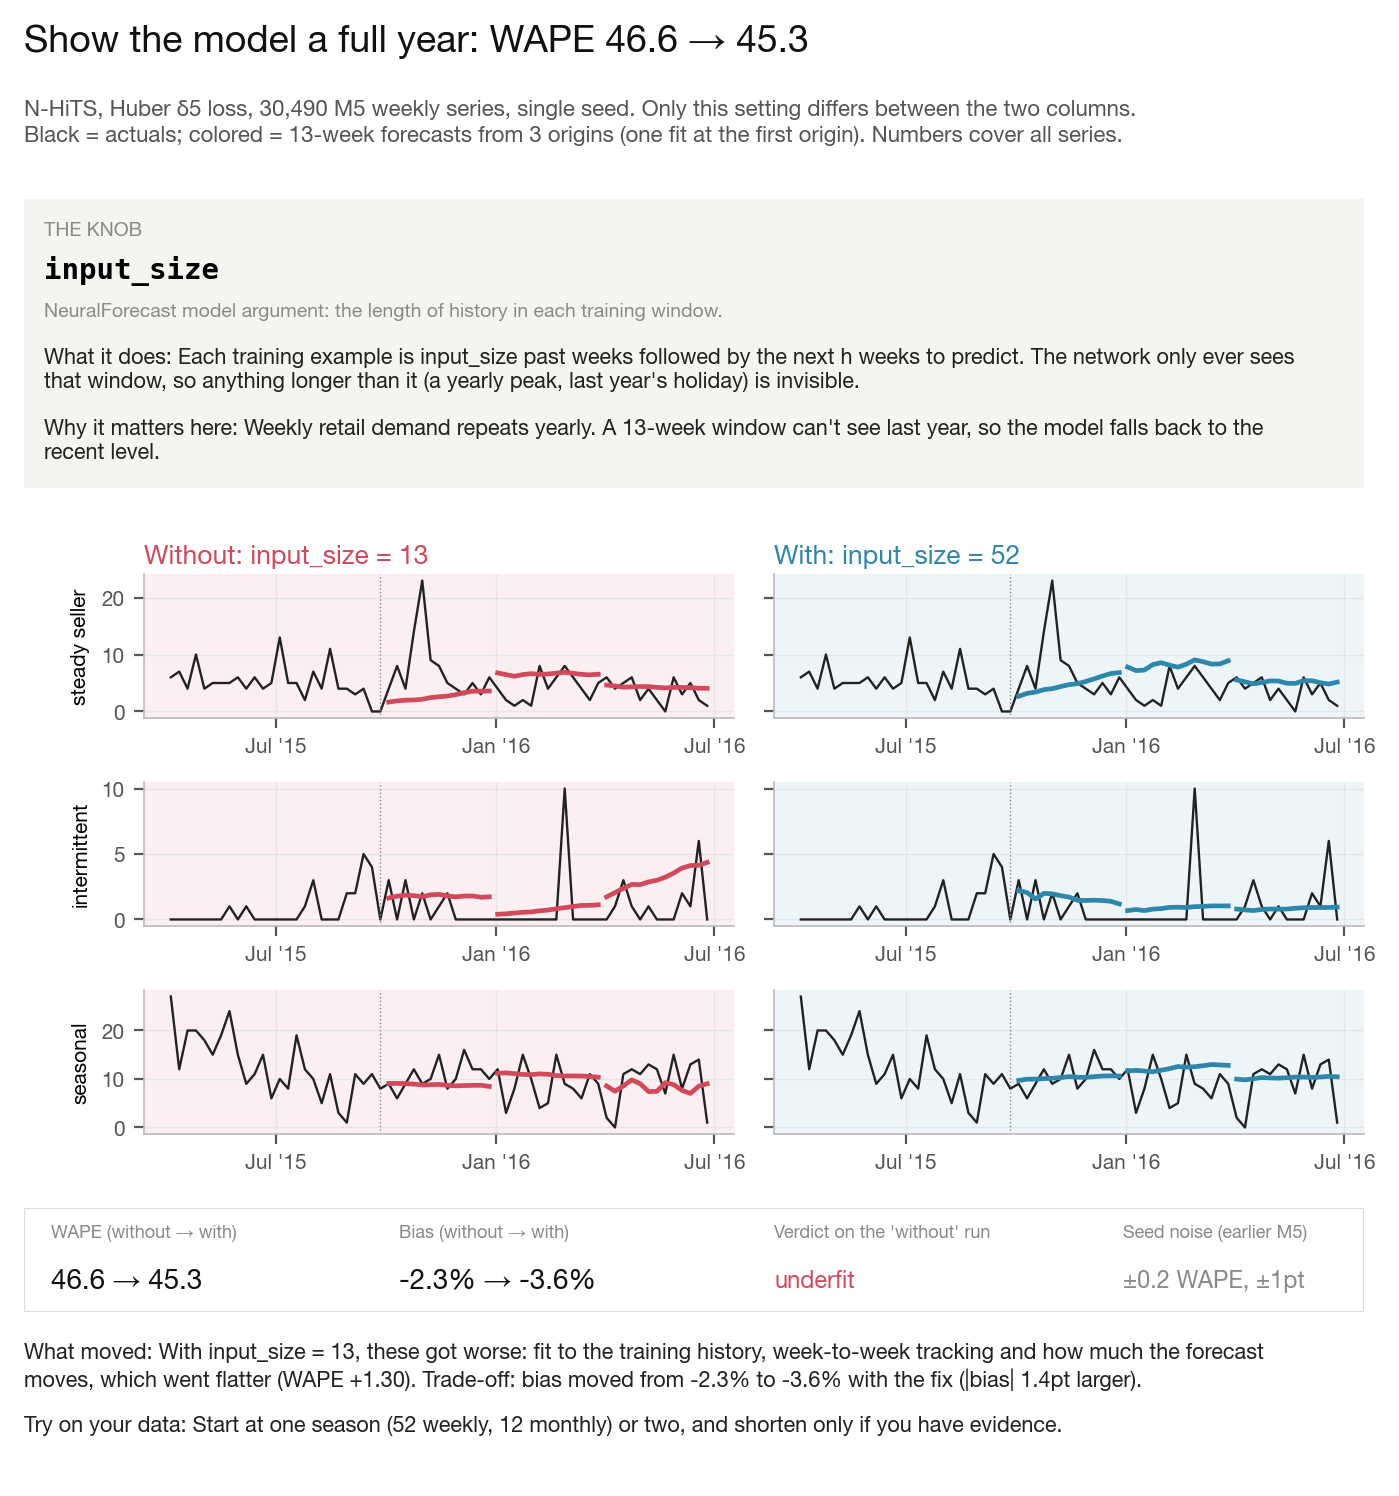

Compared: `input_size = 13` (without) vs `input_size = 52` (with). **Verdict on the 'without' run: underfit.** WAPE 46.57 → 45.27, bias -2.3% → -3.6%. With input_size = 13, these got worse: fit to the training history, week-to-week tracking and how much the forecast moves, which went flatter (WAPE +1.30). Trade-off: bias moved from -2.3% to -3.6% with the fix (|bias| 1.4pt larger).

In [5]:
display(Image(pngs["input_size"], width=800))
display(Markdown(cards.verdict_text(C["input_size"], V["input_size"])))

### Early stopping

**Claim:** give early stopping room. Validation loss on intermittent demand is noisy and often plateaus before it improves again,
so a short patience window can quit on a plateau. Both runs have the minimum-steps guard off, so patience is the only difference.
The middle panels show validation loss; the shaded span runs from the best check to the stop.

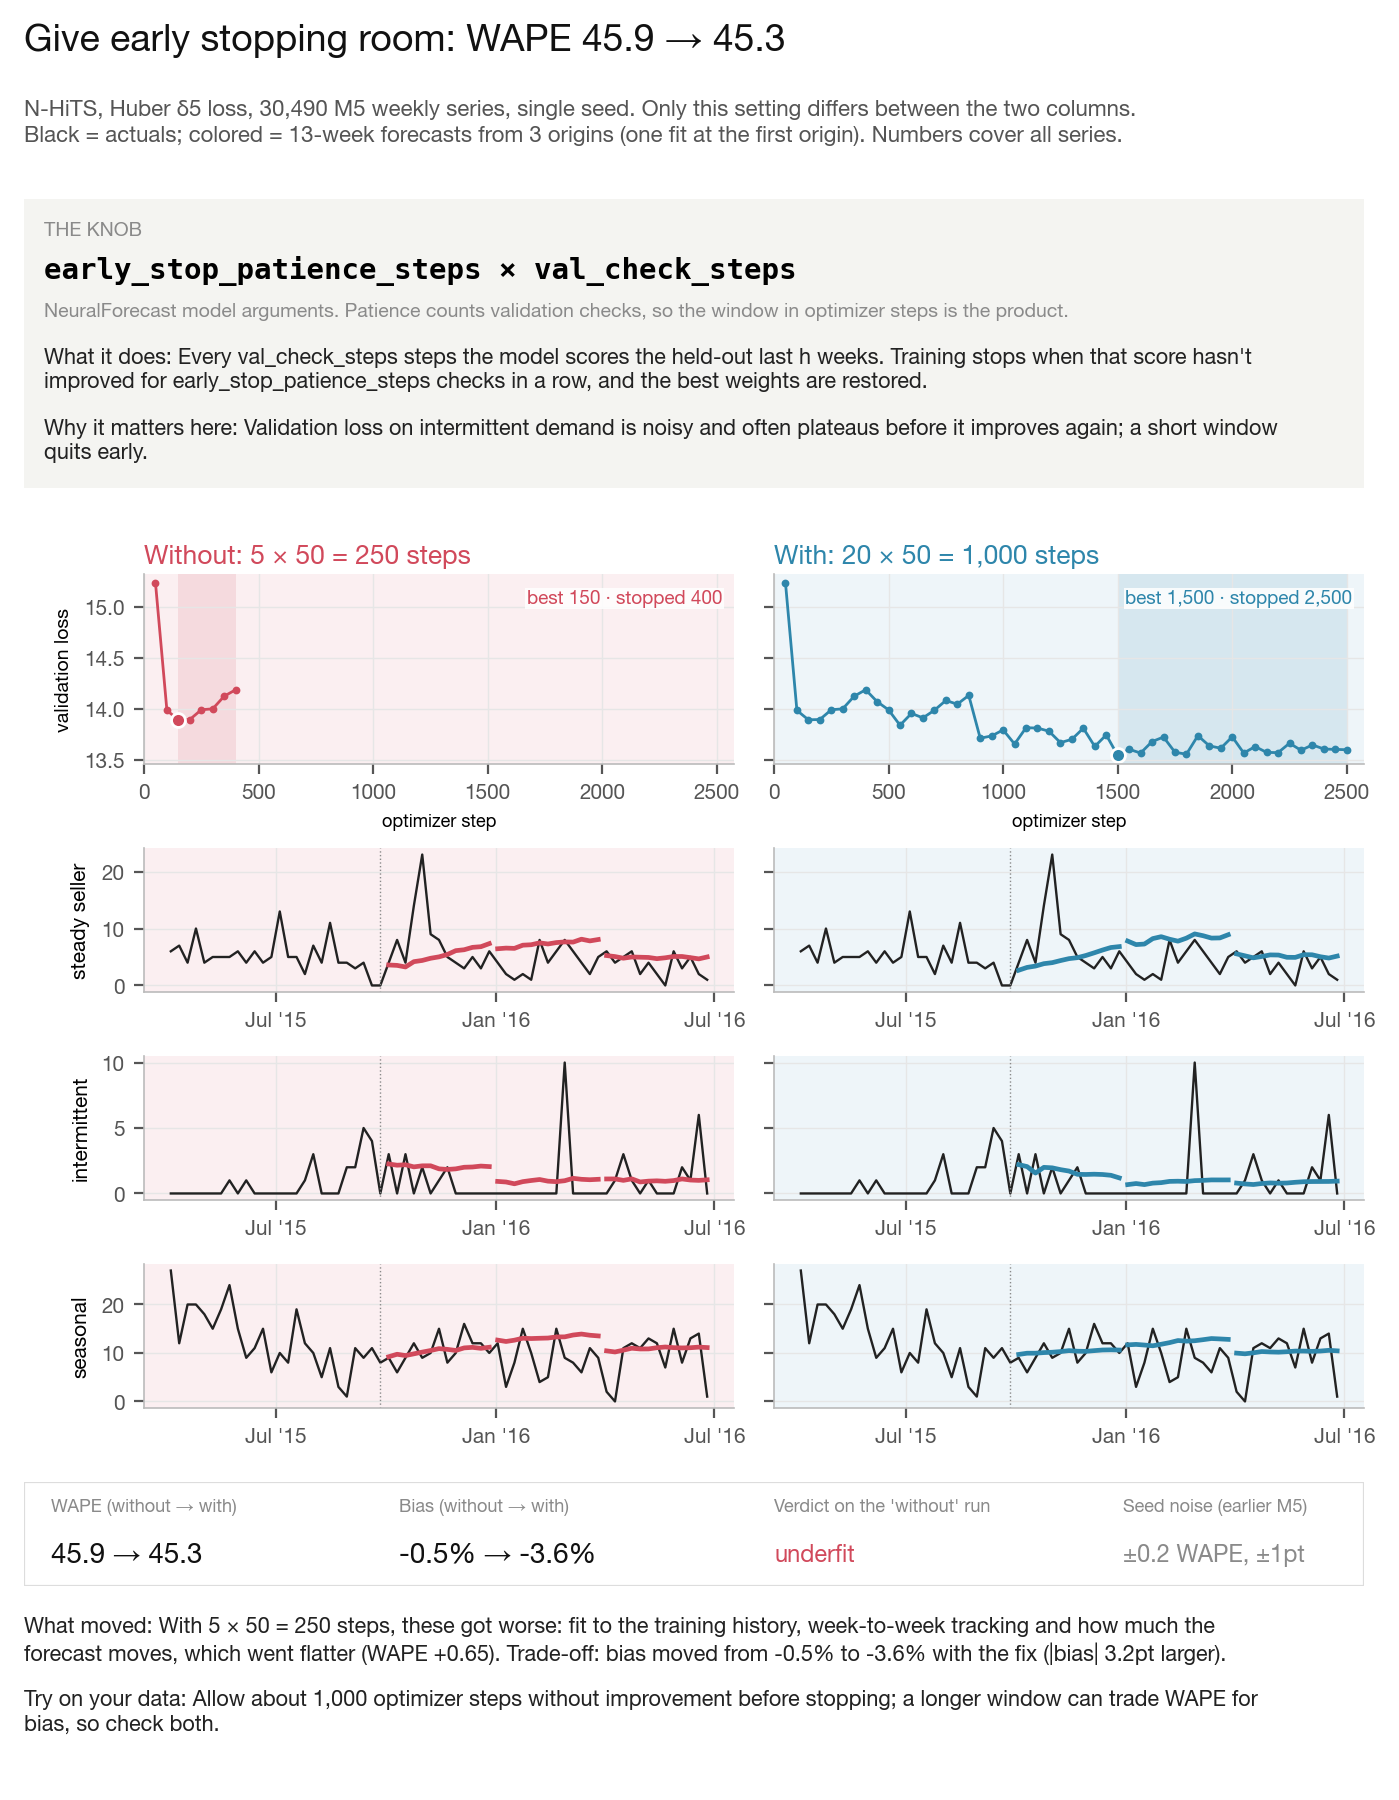

Compared: `5 × 50 = 250 steps` (without) vs `20 × 50 = 1,000 steps` (with). **Verdict on the 'without' run: underfit.** WAPE 45.93 → 45.27, bias -0.5% → -3.6%. With 5 × 50 = 250 steps, these got worse: fit to the training history, week-to-week tracking and how much the forecast moves, which went flatter (WAPE +0.65). Trade-off: bias moved from -0.5% to -3.6% with the fix (|bias| 3.2pt larger).

In [6]:
display(Image(pngs["early_stopping"], width=800))
display(Markdown(cards.verdict_text(C["early_stopping"], V["early_stopping"])))

### Loss function

**Claim:** if you use a point loss, use Huber, not MAE. The recipe's Tweedie loss is not tested on this card. MAE is minimized by the median, and the median week of an intermittent series is often zero, so an
MAE model can under-forecast total volume. The middle panels show total forecast vs total actuals over all series.

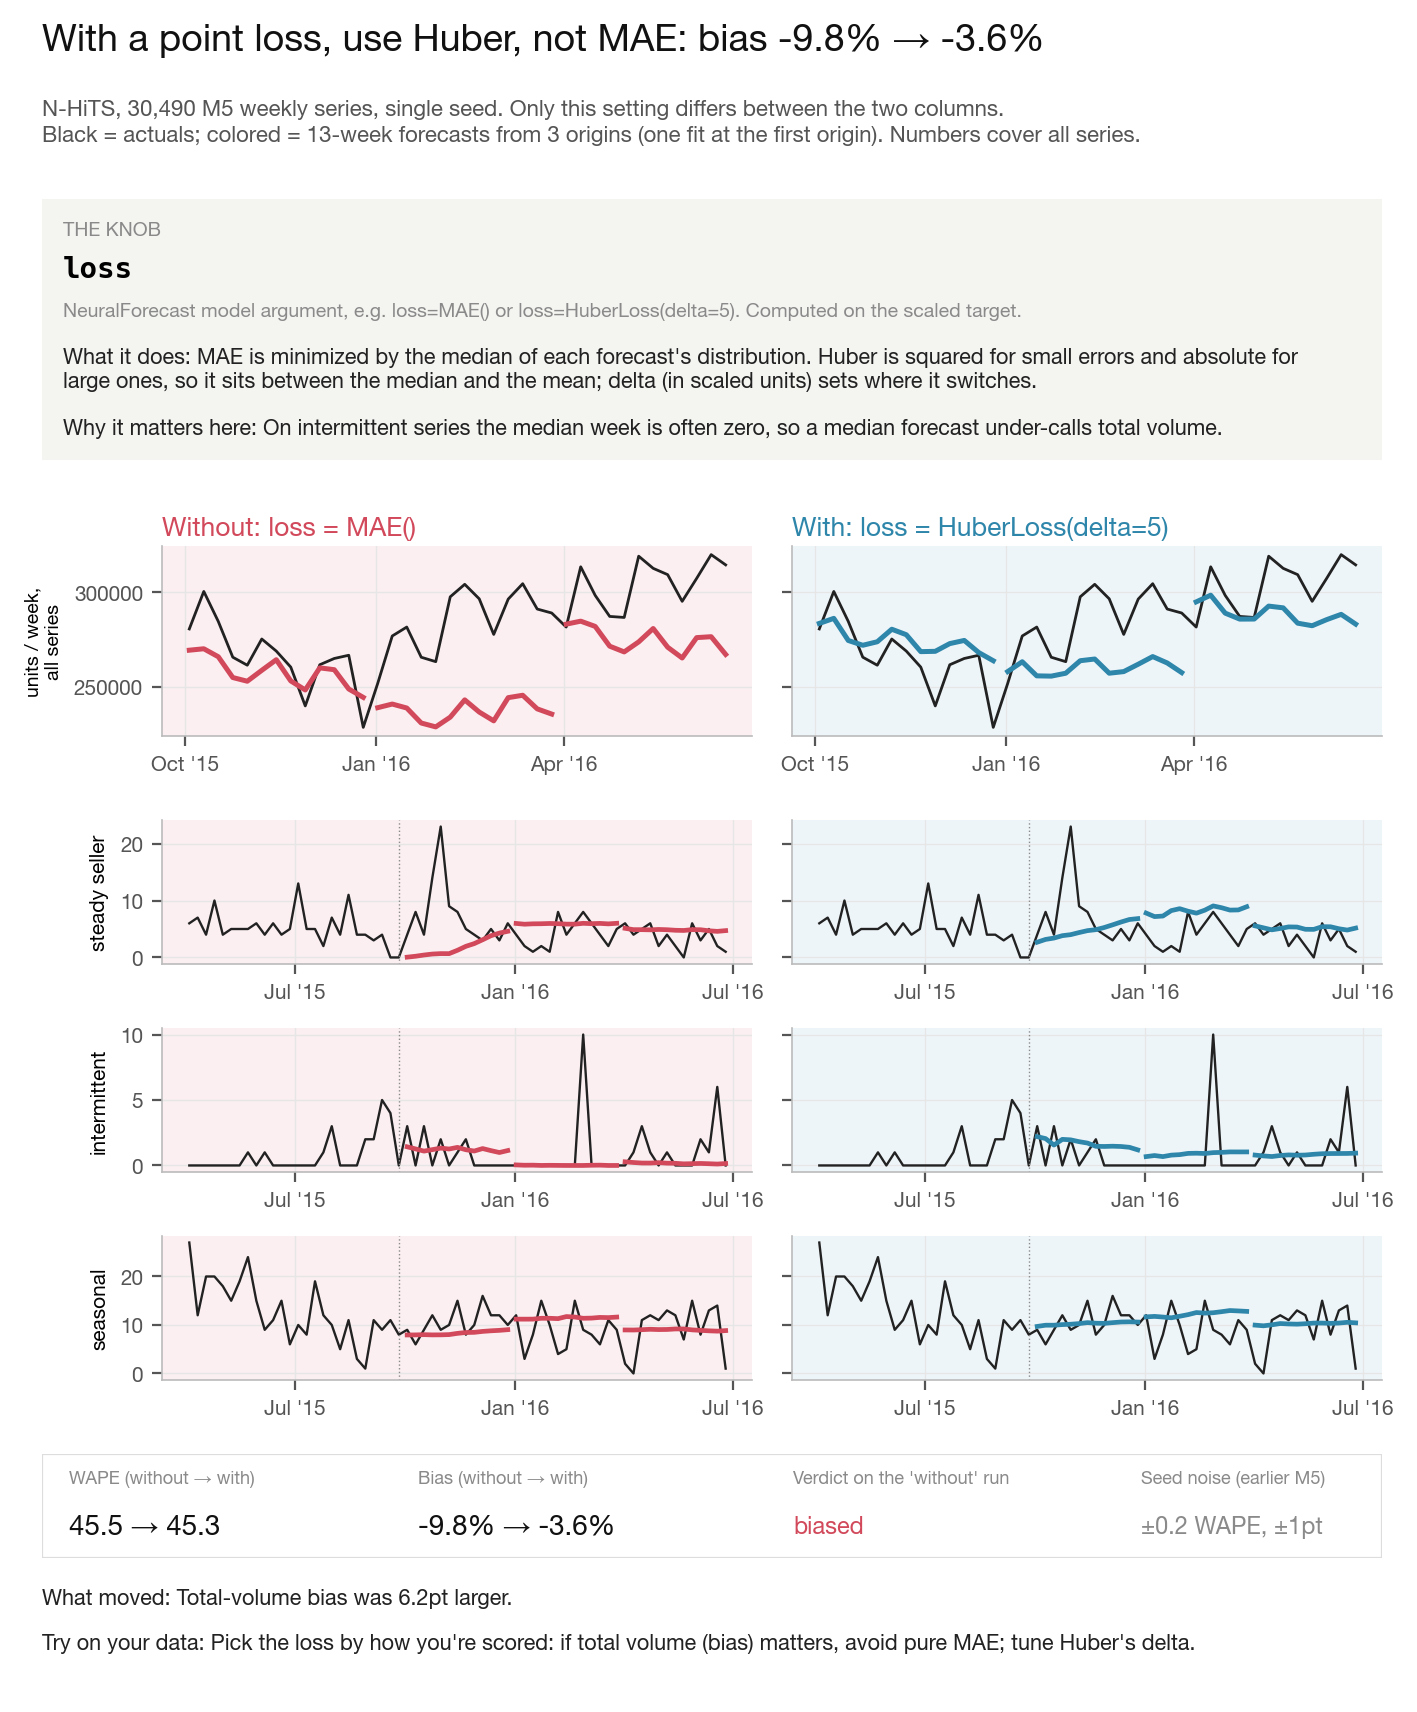

Compared: `loss = MAE()` (without) vs `loss = HuberLoss(delta=5)` (with). **Verdict on the 'without' run: biased.** WAPE 45.45 → 45.27, bias -9.8% → -3.6%. Total-volume bias was 6.2pt larger.

In [7]:
display(Image(pngs["loss"], width=800))
display(Markdown(cards.verdict_text(C["loss"], V["loss"])))

### Input scaling

**Claim:** use RevIN, not MinMax. One spike sets a window's maximum, so MinMax squeezes every other week toward zero. Note: Huber
δ5 is computed in scaled units, so on MinMax's [0, 1] scale it never caps an error and acts like squared error.

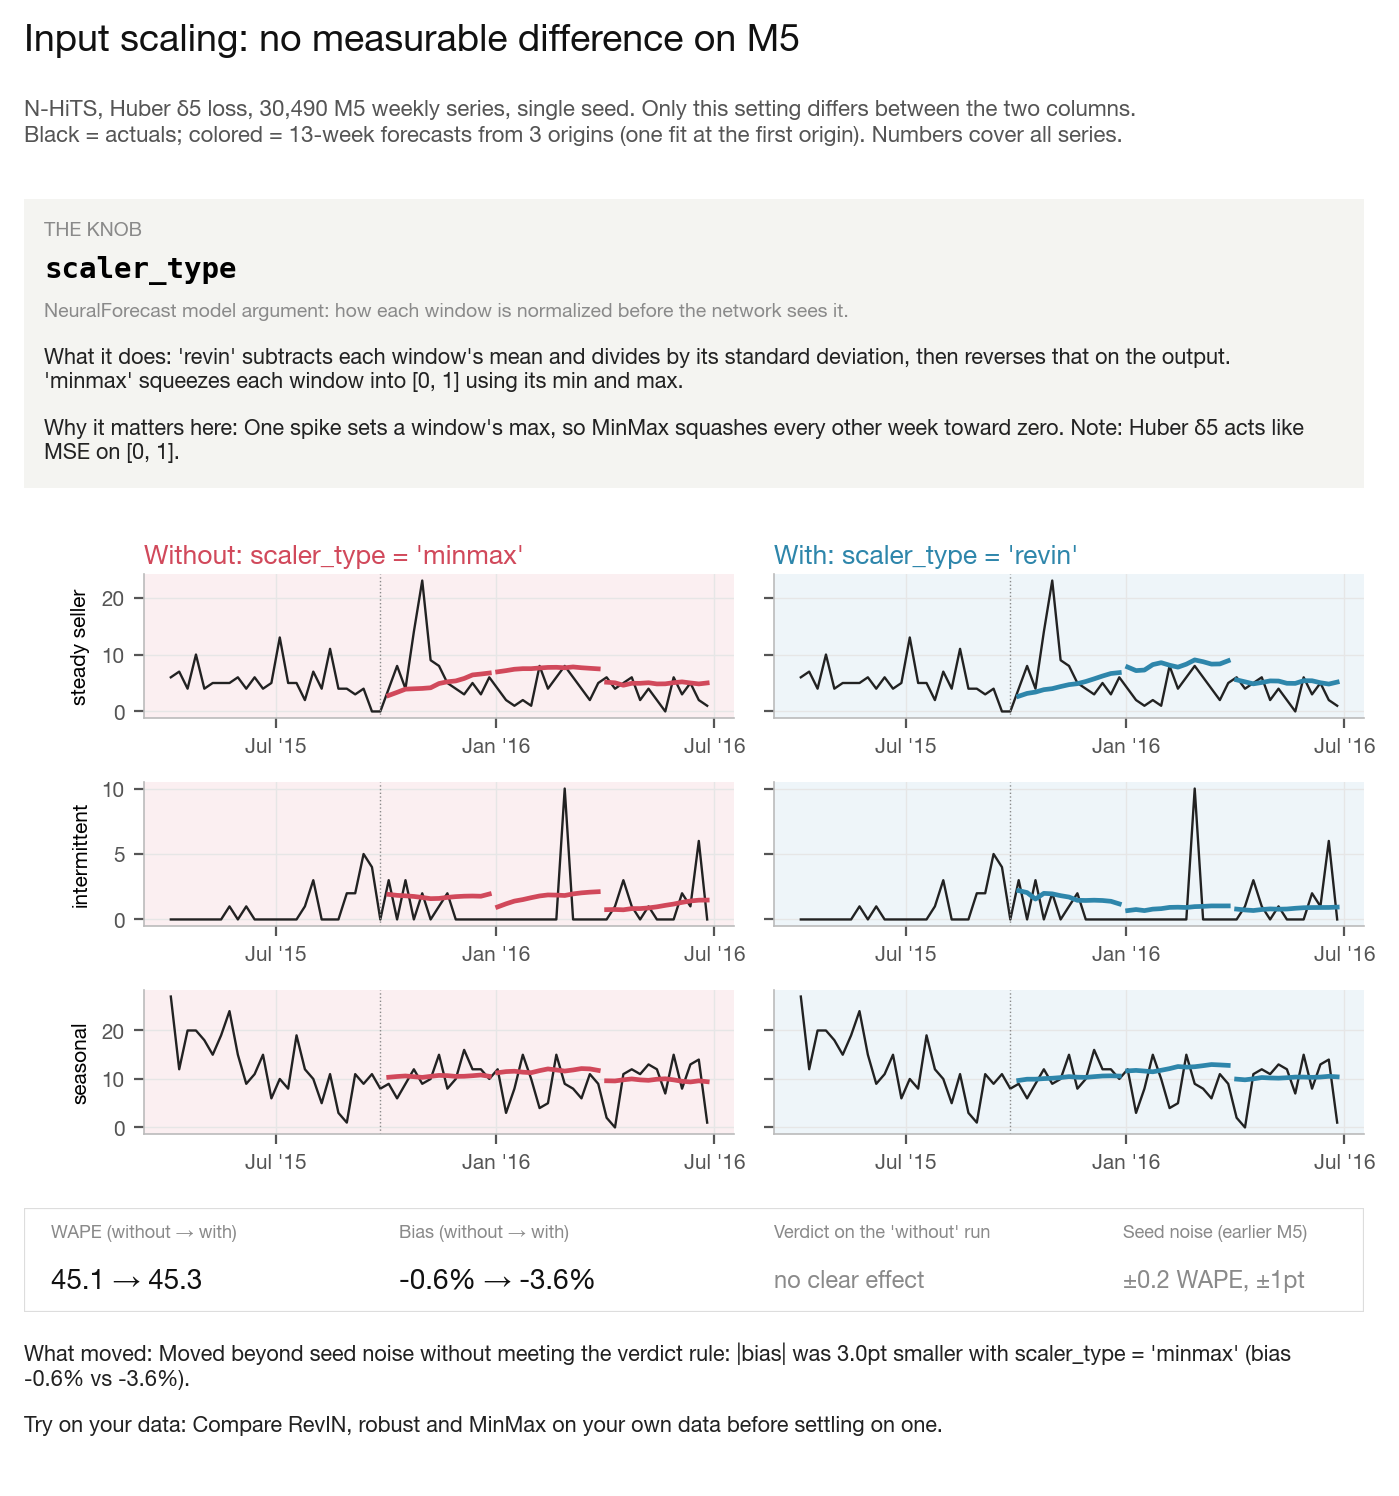

Compared: `scaler_type = 'minmax'` (without) vs `scaler_type = 'revin'` (with). **Verdict on the 'without' run: no clear effect on M5.** WAPE 45.12 → 45.27, bias -0.6% → -3.6%. Moved beyond seed noise without meeting the verdict rule: |bias| was 3.0pt smaller with scaler_type = 'minmax' (bias -0.6% vs -3.6%).

In [8]:
display(Image(pngs["scaler"], width=800))
display(Markdown(cards.verdict_text(C["scaler"], V["scaler"])))

### All five cards, and the two claims

- "A handful of settings decide whether deep learning works" is read here as: for most of the tested settings, the card's
  verdict on the wrong value is underfit, biased or both. That is weaker than "working vs not working", so the size of the
  largest gap is printed with it. Four of the five cards ran on Huber δ5.
- "Wrong settings mostly make the model underfit" is read as: more than half of the cards get the verdict underfit.

Both readings are applied by `cards.claims` in `m5knobs/figures/cards.py`.

In [9]:
display(pd.DataFrame([{"card": c["name"], "verdict on the 'without' run": cards.label_text(v["label"]),
                       "WAPE gap": round(v["wape_gap"], 2), "|bias| gap (pt)": round(v["abs_bias_gap_pts"], 1)}
                      for c in cards.CARDS for v in [V[c["key"]]]]))
claims = cards.claims(V)
display(Markdown(f"- {claims['handful']}\n- {claims['underfit']}"))

,card,verdict on the 'without' run,WAPE gap,|bias| gap (pt)
0,Gradient clipping,underfit and biased,1.13,1.7
1,Input window,underfit,1.30,-1.4
2,Early stopping,underfit,0.65,-3.2
3,Loss function,biased,0.18,6.2
4,Input scaling,no clear effect on M5,-0.15,-3.0


- 4 of 5 cards gave the wrong value a verdict of underfit or biased: Gradient clipping, Input window, Early stopping and Loss function. Largest WAPE gap among them: +1.30 (Input window, 2.9% of the 'with' run's WAPE). Verdict on the claim, read as 'for most of the tested settings, the wrong value measurably hurts': holds.
- 3 of 5 cards gave the wrong value a verdict of underfit: Gradient clipping, Input window and Early stopping. Verdict on the claim, read as 'more than half of the cards are underfit': holds.

## Early stopping, swept

The early-stopping card compares two patience windows under the recipe's learning-rate schedule, which itself depends on
`max_steps`. The sweep below gives every run the same schedule, so only the stopping rule changes: the patience window, the length
of the validation tail, how often validation runs, and whether the best weights are restored. In each panel the blue dot is the base
run and the shaded band is the base ± seed noise.

Shared settings: `{'loss': 'huber', 'huber_delta': 5.0, 'max_steps': 10000, 'min_steps': 0}`.

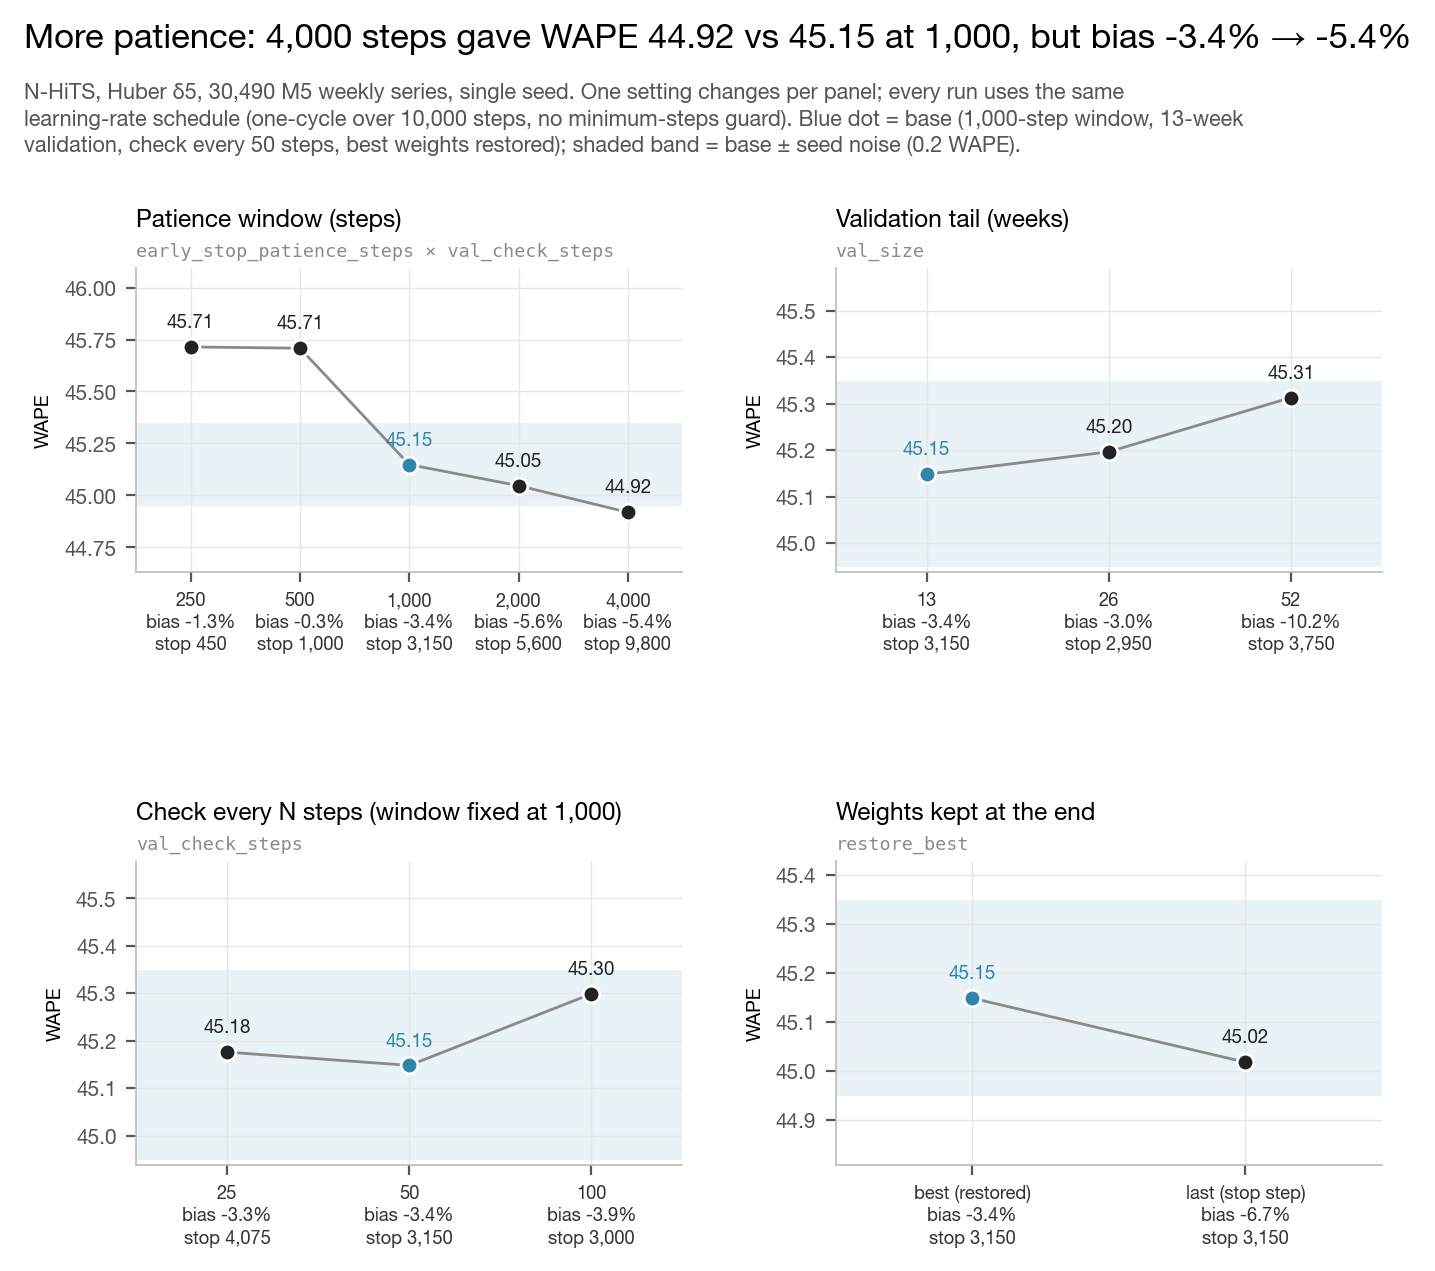

More patience: 4,000 steps gave WAPE 44.92 vs 45.15 at 1,000, but bias -3.4% → -5.4%.

In [10]:
display(Markdown(f"Shared settings: `{experiments.ES_BASE}`."))
display(Image(early_stopping.draw()[0], width=800))
S = json.load(open(os.path.join(paths.RESULTS, "es_sweep.json")))
t = pd.DataFrame([dict(window=int(lab.replace(",", "")), wape=S[a]["wape"], bias=S[a]["bias"])
                  for lab, a in early_stopping.SWEEPS[0][2]])
display(Markdown(early_stopping.headline_text(t) + "."))

In [11]:
base = S["es_p1000"]
for title, knob, xs in early_stopping.SWEEPS[1:]:
    parts = [f"{lab}: WAPE {S[a]['wape']:.2f} ({S[a]['wape'] - base['wape']:+.2f}), bias {S[a]['bias']:+.1f}%"
             for lab, a in xs if a != "es_p1000"]
    display(Markdown(f"- {title} (`{knob}`), against the base's WAPE {base['wape']:.2f} and bias {base['bias']:+.1f}%: "
                     + "; ".join(parts)))
within = [a for a in S if a != "es_p1000" and abs(S[a]["wape"] - base["wape"]) <= noise["wape"]]
display(Markdown(f"{len(within)} of {len(S) - 1} other early-stopping runs are within ±{noise['wape']} WAPE "
                 "of the base run."))
bias_moved = [f"{title.split(' (')[0].lower()}: {lab} ({S[a]['bias']:+.1f}% vs {base['bias']:+.1f}%)"
              for title, _, xs in early_stopping.SWEEPS for lab, a in xs
              if a != "es_p1000" and abs(abs(S[a]["bias"]) - abs(base["bias"])) > noise["bias"]]
display(Markdown(f"Runs whose absolute bias moved more than ±{noise['bias']:.0f}pt from the base: "
                 + ("; ".join(bias_moved) if bias_moved else "none") + "."))

- Validation tail (weeks) (`val_size`), against the base's WAPE 45.15 and bias -3.4%: 26: WAPE 45.20 (+0.05), bias -3.0%; 52: WAPE 45.31 (+0.17), bias -10.2%

- Check every N steps (window fixed at 1,000) (`val_check_steps`), against the base's WAPE 45.15 and bias -3.4%: 25: WAPE 45.18 (+0.03), bias -3.3%; 100: WAPE 45.30 (+0.15), bias -3.9%

- Weights kept at the end (`restore_best`), against the base's WAPE 45.15 and bias -3.4%: last (stop step): WAPE 45.02 (-0.13), bias -6.7%

6 of 9 other early-stopping runs are within ±0.2 WAPE of the base run.

Runs whose absolute bias moved more than ±1pt from the base: patience window: 250 (-1.3% vs -3.4%); patience window: 500 (-0.3% vs -3.4%); patience window: 2,000 (-5.6% vs -3.4%); patience window: 4,000 (-5.4% vs -3.4%); validation tail: 52 (-10.2% vs -3.4%); weights kept at the end: last (stop step) (-6.7% vs -3.4%).

## What to set

The recipe values are in notebook 02. Each line below pairs the card's computed verdict with general advice for that setting
(the advice is fixed text in `cards.CARDS`, picked by whether the card showed an effect).

In [12]:
lines = [f"- `{c['knob']}` (verdict on the wrong value: {cards.label_text(V[k]['label'])}): {V[k]['try_line']}"
         for c in cards.CARDS for k in [c["key"]]]
costly = [f"{c['name']} (|bias| {-V[c['key']]['abs_bias_gap_pts']:.1f}pt larger with the recipe value)" for c in cards.CARDS
          if V[c["key"]]["abs_bias_gap_pts"] < -noise["bias"]]
if costly:
    lines.append(f"- On {len(costly)} of {len(cards.CARDS)} cards the recipe value had more total bias than the wrong value, "
                 f"beyond the ±{noise['bias']:.0f}pt bar: " + "; ".join(costly) + ". Check bias as well as WAPE.")
display(Markdown("\n".join(lines)))

- `callbacks=[AutoClip(clip_percentile)]` (verdict on the wrong value: underfit and biased): Turn it on for Tweedie: AutoClip at the 10th percentile, or a fixed gradient_clip_val.
- `input_size` (verdict on the wrong value: underfit): Start at one season (52 weekly, 12 monthly) or two, and shorten only if you have evidence.
- `early_stop_patience_steps × val_check_steps` (verdict on the wrong value: underfit): Allow about 1,000 optimizer steps without improvement before stopping; a longer window can trade WAPE for bias, so check both.
- `loss` (verdict on the wrong value: biased): Pick the loss by how you're scored: if total volume (bias) matters, avoid pure MAE; tune Huber's delta.
- `scaler_type` (verdict on the wrong value: no clear effect on M5): Compare RevIN, robust and MinMax on your own data before settling on one.
- On 3 of 5 cards the recipe value had more total bias than the wrong value, beyond the ±1pt bar: Input window (|bias| 1.4pt larger with the recipe value); Early stopping (|bias| 3.2pt larger with the recipe value); Input scaling (|bias| 3.0pt larger with the recipe value). Check bias as well as WAPE.

Next: [04 · Gradient clipping](04_gradient_clipping.ipynb), the setting with the strongest claim attached.